# Landlab inputs for the Pioneer Fire, WA

The [landlab contract](https://github.com/gaia-hazlab/landlab_data_prep/blob/master/docs/landlab_workflow_contract.md)'s reference event (`WA4818312053120240608`), in three steps:

1. **Stage** every dataset the landlab workflow reads into one Zarr store, each on its native grid.
2. **Align** the store onto the contract's 10 m UTM grid with `gaia align`, and look at it.
3. **Convert** the aligned store to GeoTIFF and ESRI ASCII grids with GDAL alone ([scripts/landlab-inputs.sh](https://github.com/gaia-hazlab/gaia-cli/blob/main/scripts/landlab-inputs.sh)).

The soil-derived node fields (porosity, cohesion, ...) are not computed here: landlab_data_prep derives them from the seven SOLUS layers.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import rioxarray  # noqa: F401  registers .rio
import xarray as xr
from matplotlib.colors import LightSource, to_rgba
from matplotlib.patches import Patch

from zarr.storage import ObjectStore
from obstore.store import S3Store

from gaia_cli import stations

#%config InlineBackend.figure_format = 'retina'

## 1. Stage

[examples/pioneer.yaml](https://github.com/gaia-hazlab/gaia-cli/blob/main/examples/pioneer.yaml) lists the required inputs (DEM, burn severity, the seven SOLUS soil layers, STATSGO K-factor, NLCD), plus PRISM and Synoptic precipitation for an atmospheric river in December 2025. The static layers ignore the window. Its AOI, [examples/pioneer-aoi.geojson](https://github.com/gaia-hazlab/gaia-cli/blob/main/examples/pioneer-aoi.geojson), is the perimeter's bounding box, and meets five BAER fires, so `fire` and `year` choose the 2024 Pioneer Fire. The stores go to the `scratch/public` prefix on Kopah, which anyone can read and which is deleted after 2 weeks; the landlab files go to `/tmp`.

In [2]:
!cat pioneer.yaml

# Pioneer Fire, WA (2024): the landlab workflow's reference event. Its required inputs
# (DEM, burn severity, SOLUS soil, STATSGO K-factor, land cover), plus station and PRISM
# precipitation for the December 2025 atmospheric river. Check with --dry-run, then stage:
#   gaia stage --config examples/pioneer.yaml --dry-run
#   gaia stage --config examples/pioneer.yaml -o /tmp/pioneer
# pioneer-landlab.ipynb aligns the result onto the landlab grid over the same AOI.
name: pioneer
attrs:
  title: Pioneer Fire landlab inputs, with the December 2025 atmospheric river
aoi: pioneer-aoi.geojson            # relative to this file; also gaia align --aoi
window: 2025-12-01/2025-12-16       # whole days, end included; static layers ignore it
datasets:
  dem/usgs10m: {}
  burn-severity: {fire: pioneer, year: 2024}   # the AOI meets five BAER fires
  soil/solus100: {}
  soil/statsgo: {}
  nlcd: {year: 2021}
  prism: {variables: [ppt, tmin, tmax]}
  synoptic: {}


In [3]:
scratch = "s3://gaia/scratch/public"
staged = f"{scratch}/pioneer"                # gaia stage -o
aligned = f"{scratch}/pioneer-10m"           # gaia align -o
staged_zarr = f"{staged}/pioneer.zarr"       # gaia align -i
aligned_zarr = f"{aligned}/pioneer-10m.zarr"
# GDAL reads scratch/public anonymously through /vsis3/: with /vsicurl/, its search for
# dimension arrays outside the store prints ~100 warnings (dev/gdal-zarr/upstream-issue.md)
gdal_env = "AWS_S3_ENDPOINT=s3.kopah.uw.edu AWS_NO_SIGN_REQUEST=YES AWS_VIRTUAL_HOSTING=FALSE"
aligned_vsis3 = "/vsis3/" + aligned_zarr.removeprefix("s3://")
landlab_dir = "/tmp/pioneer-landlab"         # Landlab needs local files

In [4]:
!gaia stage --config pioneer.yaml -o {staged} --overwrite

11:52:28 [   1.2s] stagefile: Wrote s3://gaia/scratch/public/pioneer/stage.yaml
11:52:28 [   1.2s] runner: dem/usgs10m: loading (static)
11:52:28 [   1.2s] datasets.dem: DEM: opening https://prd-tnm.s3.amazonaws.com/StagedProducts/Elevation/13/TIFF/USGS_Seamless_DEM_13.vrt
11:52:33 [   6.0s] io: Writing Zarr to s3://gaia/scratch/public/pioneer/pioneer.zarr
11:52:37 [  10.4s] io: Saved s3://gaia/scratch/public/pioneer/pioneer.zarr
11:52:37 [  10.6s] io: Wrote STAC item s3://gaia/scratch/public/pioneer/pioneer.json
11:52:37 [  10.6s] runner: burn-severity: loading (static)
11:52:38 [  11.4s] datasets.burn_severity: BAER: pioneer_wa4818312053120240608_sbs (2024)
11:52:44 [  16.9s] datasets.burn_severity: BAER: exporting raster 3727 (1092 x 1656 cells)
11:52:47 [  19.8s] io: Writing Zarr to s3://gaia/scratch/public/pioneer/pioneer.zarr
11:52:50 [  23.8s] io: Saved s3://gaia/scratch/public/pioneer/pioneer.zarr
11:52:51 [  23.9s] io: Wrote STAC item s3://gaia/scratch/public/pioneer/pioneer.j

## 2. Align onto the contract grid

`--crs utm --res 10 --aoi` gives the contract's grid: the UTM zone of the AOI (EPSG:32610), 10 m cells, the AOI's bounds snapped outward to multiples of 10 m, and NaN in cells whose centre is outside the AOI. The `-m` options are the contract's resampling methods; without them, DEMs use `bilinear` and categories `mode`. PRISM goes `nearest` (its default, `conservative`, becomes `nearest` onto a finer grid), and Synoptic's stations pass through unchanged.

In [5]:
!gaia align -i {staged_zarr} -o {aligned} \
    --crs utm --res 10 --aoi pioneer-aoi.geojson \
    -m dem/usgs10m=cubic \
    -m soil/solus100=bilinear \
    -m rasters/nlcd=nearest \
    -m rasters/burn-severity=nearest \
    -m rasters/prism/tmin=bilinear \
    -m rasters/prism/tmax=bilinear \
    --overwrite

11:54:08 [   2.4s] align: time target rasters/prism (18 step(s))
11:54:12 [   5.8s] align: grid target EPSG:32610 at 10.0 (3309 x 2182 cells)
11:54:12 [   5.8s] align: regridding dem/usgs10m/elevation (cubic)
11:54:15 [   8.9s] align: regridding rasters/burn-severity/burn_severity (nearest)
11:54:18 [  11.6s] align: regridding rasters/nlcd/landcover (nearest)
11:54:19 [  13.1s] align: regridding rasters/prism/precipitation (nearest)
11:54:22 [  15.8s] align: regridding rasters/prism/tmax (bilinear)
11:54:27 [  20.6s] align: regridding rasters/prism/tmin (bilinear)
11:54:32 [  25.8s] align: regridding soil/solus100/anylithicdpt (bilinear)
11:54:34 [  28.3s] align: regridding soil/solus100/cec7 (bilinear)
11:54:37 [  30.7s] align: regridding soil/solus100/claytotal (bilinear)
11:54:39 [  33.1s] align: regridding soil/solus100/dbovendry (bilinear)
11:54:42 [  35.6s] align: regridding soil/solus100/ph1to1h2o (bilinear)
11:54:44 [  38.0s] align: regridding soil/solus100/sandtotal (bilinear)

In [6]:
# Kopah (Ceph) S3 access. obstore needs the endpoint explicitly, and path-style requests.
# Anything under scratch/public/ is anonymously readable, so no credentials needed
s3gaia = S3Store(
    bucket="gaia",
    prefix=aligned_zarr.removeprefix("s3://gaia/"),
    endpoint="https://s3.kopah.uw.edu",
    region="us-west-2",  # not actually used with kopah
    virtual_hosted_style_request=False,
    skip_signature=True, # anonymous read-only access
)

# Zarr-aware handler for reading from S3
gaia_zarr_store = ObjectStore(s3gaia, read_only=True)

In [7]:
dt = xr.open_datatree(gaia_zarr_store, engine="zarr", zarr_format=3, consolidated=True)
dt.groups

('/',
 '/dem',
 '/rasters',
 '/soil',
 '/stations',
 '/dem/usgs10m',
 '/rasters/burn-severity',
 '/rasters/nlcd',
 '/rasters/prism',
 '/soil/solus100',
 '/soil/statsgo',
 '/stations/synoptic')

## A look at the aligned store

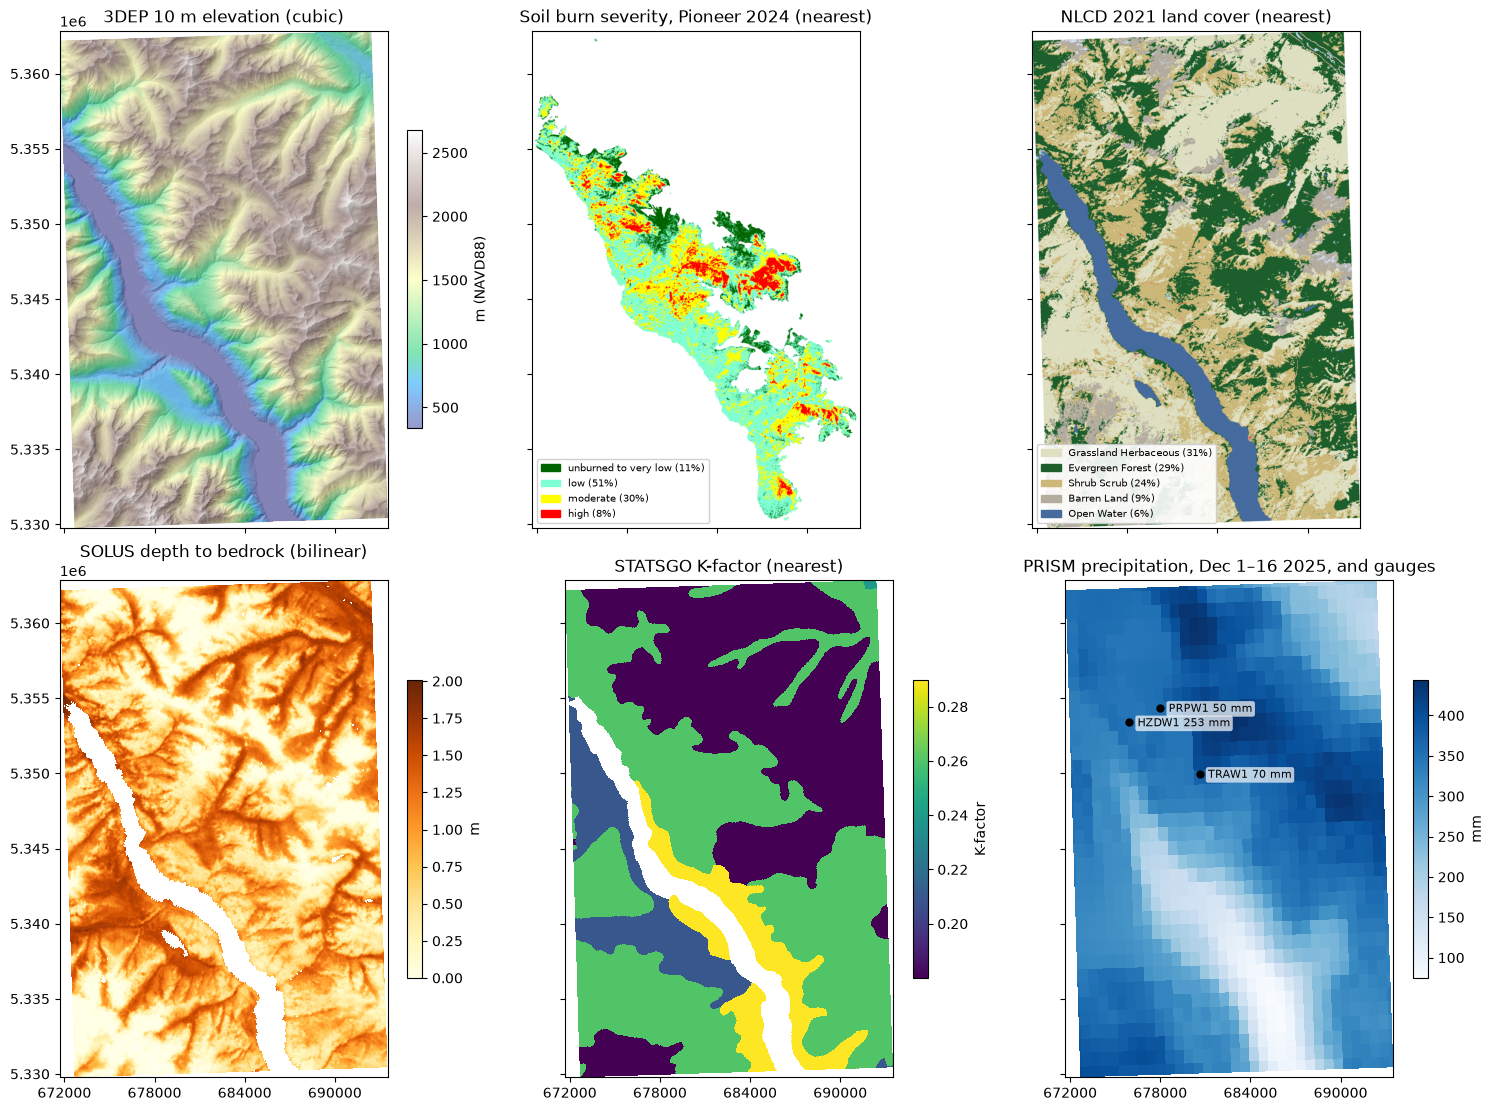

In [8]:
def categories(da, min_share=0.005, by_share=True):
    """RGBA image and legend handles from a categorical variable's CF flag attributes."""
    codes = da.attrs["flag_values"]
    names = da.attrs["flag_meanings"].split()
    colors = da.attrs["flag_colors"].split()
    rgba = np.ones(da.shape + (4,))  # white where there's no class
    handles = []
    for code, name, color in zip(codes, names, colors):
        cells = (da == code).values
        rgba[cells] = to_rgba(color)
        share = cells.sum() / da.notnull().sum().item()
        if share >= min_share:
            handles.append((share, Patch(color=color, label=f"{name.replace('_', ' ')} ({share:.0%})")))
    if by_share:
        handles.sort(key=lambda h: -h[0])
    return rgba, [h for _, h in handles]


elevation = dt["dem/usgs10m"].elevation
soil = dt["soil/solus100"]
prism = dt["rasters/prism"].sel(time=slice("2025-12-01", "2025-12-16"))
precip = prism.precipitation.sum("time", min_count=1)

# Gauge totals over the same PRISM days (12:00 UTC to 12:00 UTC)
t0, t1 = prism.time_bounds.values[0, 0], prism.time_bounds.values[-1, 1]
hourly = stations.to_grid(dt["stations/synoptic"].to_dataset(), freq="1h", how="sum")
gauge_total = hourly.precipitation.sel(time=slice(t0 + np.timedelta64(1, "h"), t1)).sum("time", min_count=1)
xy = gpd.GeoSeries(hourly.geometry.values, crs="EPSG:4326").to_crs(precip.rio.crs)

fig, axes = plt.subplots(2, 3, figsize=(15, 11), layout="constrained", sharex=True, sharey=True)
x, y = elevation.x.values, elevation.y.values
extent = [x[0] - 5, x[-1] + 5, y[-1] - 5, y[0] + 5]

ax = axes[0, 0]
shade = LightSource(azdeg=315, altdeg=45).hillshade(elevation.fillna(elevation.min()).values, dx=10, dy=10)
ax.imshow(np.where(elevation.notnull(), shade, np.nan), extent=extent, cmap="gray")
elevation.plot.imshow(ax=ax, cmap="terrain", alpha=0.5, cbar_kwargs={"label": "m (NAVD88)", "shrink": 0.6})
ax.set_title("3DEP 10 m elevation (cubic)")

# burn severity's classes are ordered, NLCD's are listed by area
for ax, da, by_share, title in [
    (axes[0, 1], dt["rasters/burn-severity"].burn_severity, False, "Soil burn severity, Pioneer 2024 (nearest)"),
    (axes[0, 2], dt["rasters/nlcd"].landcover, True, "NLCD 2021 land cover (nearest)"),
]:
    rgba, handles = categories(da, by_share=by_share)
    ax.imshow(rgba, extent=extent)
    ax.legend(handles=handles, loc="lower left", fontsize=7, framealpha=0.9)
    ax.set_title(title)

(soil.anylithicdpt / 100).plot.imshow(ax=axes[1, 0], cmap="YlOrBr", cbar_kwargs={"label": "m", "shrink": 0.6})
axes[1, 0].set_title("SOLUS depth to bedrock (bilinear)")
dt["soil/statsgo"].kffact.plot.imshow(ax=axes[1, 1], cmap="viridis", cbar_kwargs={"label": "K-factor", "shrink": 0.6})
axes[1, 1].set_title("STATSGO K-factor (nearest)")

ax = axes[1, 2]
precip.plot.imshow(ax=ax, cmap="Blues", cbar_kwargs={"label": "mm", "shrink": 0.6})
ax.scatter(xy.x, xy.y, c="k", s=25)
for px, py, sid, total in zip(xy.x, xy.y, hourly.station.values, gauge_total.values):
    label = f"{sid} {total:.0f} mm" if np.isfinite(total) else f"{sid} (no reports)"
    ax.annotate(label, (px, py), xytext=(6, -3), textcoords="offset points", fontsize=8,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, lw=0))
ax.set_title("PRISM precipitation, Dec 1–16 2025, and gauges")

for ax in axes.flat:
    ax.set(xlabel="", ylabel="", aspect="equal", xlim=extent[:2], ylim=extent[2:])
    ax.xaxis.set_major_locator(plt.MaxNLocator(4))

Accumulated precipitation at each gauge, against PRISM in the gauge's cell. PRISM's totals are known at the end of each day (12:00 UTC); hours without a report count as zero.

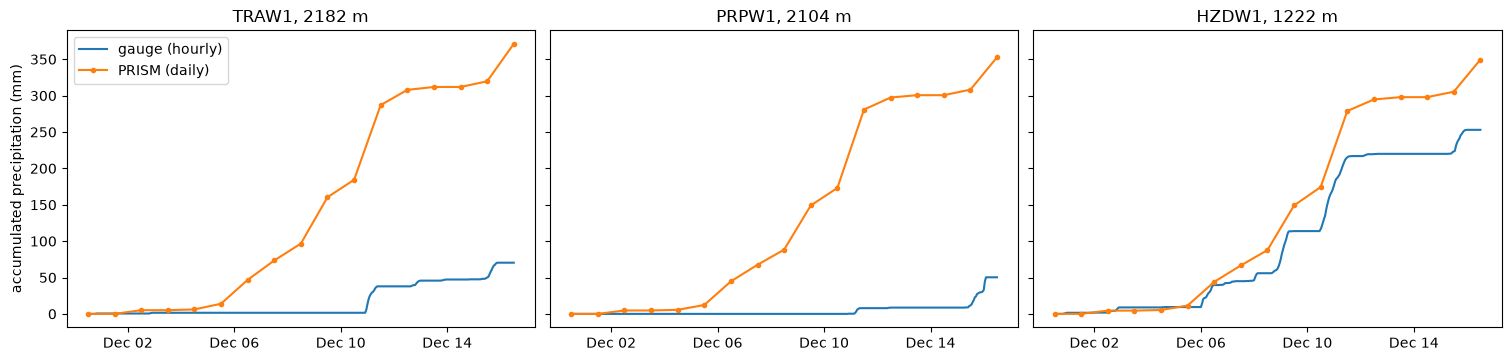

In [9]:
fig, axes = plt.subplots(1, hourly.sizes["geometry"], figsize=(15, 3.5), sharey=True, layout="constrained")
ends = prism.time_bounds.values[:, 1]
for i, ax in enumerate(axes):
    gauge = hourly.isel(geometry=i)
    in_window = gauge.precipitation.sel(time=slice(t0 + np.timedelta64(1, "h"), t1))
    cell = prism.precipitation.sel(x=xy.x.iloc[i], y=xy.y.iloc[i], method="nearest")
    ax.plot(in_window.time, in_window.fillna(0).cumsum("time"), label="gauge (hourly)")
    ax.plot(np.r_[t0, ends], np.r_[0, cell.cumsum("time").values], marker="o", ms=3, label="PRISM (daily)")
    ax.set_title(f"{gauge.station.item()}, {gauge.elevation.item():.0f} m")
    ax.xaxis.set_major_locator(plt.matplotlib.dates.DayLocator(interval=4))
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d"))
axes[0].set_ylabel("accumulated precipitation (mm)")
axes[0].legend(loc="upper left");

## 3. Landlab inputs with GDAL

GDAL reads the aligned store directly: each array is a subdataset with its CRS (`_CRS`), nodata (the Zarr `fill_value`) and, for packed soil layers, its `scale_factor`. Remote stores are read through `/vsis3/` (or `/vsicurl/`), using the store's consolidated metadata.

In [10]:
!{gdal_env} gdal raster info 'ZARR:"{aligned_vsis3}"' 2>/dev/null | grep NAME

  SUBDATASET_1_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/dem/usgs10m/elevation
  SUBDATASET_2_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/rasters/burn-severity/burn_severity
  SUBDATASET_3_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/rasters/nlcd/landcover
  SUBDATASET_4_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/rasters/prism/precipitation
  SUBDATASET_5_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/rasters/prism/time_bounds
  SUBDATASET_6_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/rasters/prism/tmax
  SUBDATASET_7_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/rasters/prism/tmin
  SUBDATASET_8_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/soil/solus100/anylithicdpt
  SUBDATASET_9_NAME=ZARR:"/vsis3/gaia/scratch/public/pioneer-10m/pioneer-10m.zarr":/soil/solus100/cec7
  SUBDATASET_10_NAME=ZARR

Since every raster is already on the contract grid, writing landlab's files is a format conversion plus the contract's nodata rules, a few `gdal` commands per layer. [scripts/landlab-inputs.sh](https://github.com/gaia-hazlab/gaia-cli/blob/main/scripts/landlab-inputs.sh) writes a float32 GeoTIFF and an ESRI ASCII grid for each layer:

- nodata (NaN, or a packed integer's fill) becomes `-9999`;
- soil layers are unscaled (`cec7` is stored as tenths, `ph1to1h2o` and `dbovendry` as hundredths);
- burn severity keeps classes 2–4 and sets everything else to 1, with no nodata.

Layers the model reads as they are get their Landlab field names (`topographic__elevation`, `burn__severity`, `landcover`, `kffact`); the soil layers keep SOLUS's names.

In [11]:
!{gdal_env} ../scripts/landlab-inputs.sh {aligned_vsis3} {landlab_dir}

dem/usgs10m/elevation -> /tmp/pioneer-landlab/topographic__elevation.{tif,asc}
rasters/nlcd/landcover -> /tmp/pioneer-landlab/landcover.{tif,asc}
soil/statsgo/kffact -> /tmp/pioneer-landlab/kffact.{tif,asc}
soil/solus100/anylithicdpt -> /tmp/pioneer-landlab/anylithicdpt.{tif,asc}
soil/solus100/cec7 -> /tmp/pioneer-landlab/cec7.{tif,asc}
soil/solus100/claytotal -> /tmp/pioneer-landlab/claytotal.{tif,asc}
soil/solus100/dbovendry -> /tmp/pioneer-landlab/dbovendry.{tif,asc}
soil/solus100/ph1to1h2o -> /tmp/pioneer-landlab/ph1to1h2o.{tif,asc}
soil/solus100/sandtotal -> /tmp/pioneer-landlab/sandtotal.{tif,asc}
soil/solus100/silttotal -> /tmp/pioneer-landlab/silttotal.{tif,asc}
rasters/burn-severity/burn_severity -> /tmp/pioneer-landlab/burn__severity.{tif,asc}


In [12]:
!head -6 {landlab_dir}/topographic__elevation.asc | cut -c 1-60

ncols        2182
nrows        3309
xllcorner    671690.000000000000
yllcorner    5329770.000000000000
cellsize     10.000000000000
NODATA_value -9999


The contract's grid check: every output has the same CRS, transform, shape and nodata.

In [13]:
rows = []
for tif in sorted(Path(landlab_dir).glob("*.tif")):
    with rasterio.open(tif) as src:
        a = src.read(1, masked=True)
        rows.append({
            "layer": tif.stem, "crs": str(src.crs), "transform": tuple(src.transform)[:6],
            "shape": src.shape, "nodata": "none" if src.nodata is None else src.nodata,
            "min": a.min(), "max": a.max(),
            "nodata cells": int(a.mask.sum()),
        })
check = pd.DataFrame(rows).set_index("layer")
assert check[["crs", "transform", "shape"]].nunique().eq(1).all()
check.drop(columns="transform")

,crs,shape,nodata,min,max,nodata cells
layer,,,,,,
anylithicdpt,EPSG:32610,"(3309, 2182)",-9999.0,0.000000,201.000000,925578
burn__severity,EPSG:32610,"(3309, 2182)",none,1.000000,4.000000,0
cec7,EPSG:32610,"(3309, 2182)",-9999.0,15.500000,55.299999,925578
claytotal,EPSG:32610,"(3309, 2182)",-9999.0,2.000000,13.000000,925578
dbovendry,EPSG:32610,"(3309, 2182)",-9999.0,0.750000,1.300000,925578
kffact,EPSG:32610,"(3309, 2182)",-9999.0,0.180000,0.290000,903138
landcover,EPSG:32610,"(3309, 2182)",-9999.0,11.000000,95.000000,479477
ph1to1h2o,EPSG:32610,"(3309, 2182)",-9999.0,4.430000,6.620000,925578
sandtotal,EPSG:32610,"(3309, 2182)",-9999.0,46.000000,74.000000,925578
